# Chương 1 — Milestone 1: Thu thập Dữ liệu (Data Crawling)

Báo cáo thuộc đồ án *Nhập môn Khoa học Dữ liệu* — Đề tài: **Xây dựng tập dữ liệu và hệ thống xử lý bài báo khoa học từ arXiv**.

---

## 1.1. Phương pháp & Quy trình Thu thập Dữ liệu  

Để việc thu thập gần 25.000 bài báo diễn ra ổn định và dễ kiểm soát lỗi trên Google Colab, nhóm tách pipeline làm 3 khâu độc lập:

1. **Khám phá bài báo (Entry Discovery):**  
   Nhóm sử dụng thư viện `arxiv.py` gọi trực tiếp vào arXiv API theo 5 dải ID đã chia cho 5 thành viên (tổng cộng 24.999 bài). Ở bước này, pipeline thu thập các trường metadata cốt lõi: tiêu đề (`title`), danh sách tác giả (`authors`), danh mục chính (`primary_category`), các danh mục phụ (`categories`), ngày nộp bản đầu tiên (`submission_date`), lịch sử cập nhật (`revised_dates`), DOI, `venue` và tổng số phiên bản (`num_versions`).
   *Xử lý lỗi thực tế:* Khi đọc danh sách ID từ bảng phân công, một số công cụ bảng tính tự động hiểu nhầm mã bài báo là số thập phân và cắt mất số `0` ở đầu hoặc cuối (ví dụ `.03848` bị cắt hoặc mất số `0` đuôi). Nhóm đã viết hàm `normalize_arxiv_id` để ép chuẩn lại toàn bộ ID về đúng định dạng trước khi gửi request.

2. **Tải mã nguồn toàn văn (Full-Text Source Download):**  
   Bám sát yêu cầu đề bài là phải lấy đủ mọi phiên bản chỉnh sửa của bài báo, nhóm quét tải toàn bộ các version ($v1, v2, \dots, v_n$) qua endpoint `/src/{arxiv_id}vN` trên cụm máy chủ `export.arxiv.org`.  
   *Tối ưu lưu trữ:* Gói nguồn tải về từ arXiv thường là tệp nén `.tar.gz` khá nặng do chứa nhiều hình ảnh minh họa. Ngay sau khi tải và giải nén, script của nhóm tự động lọc và chỉ giữ lại các file văn bản `.tex` và `.bib`, xóa toàn bộ file ảnh/nhị phân (`.png`, `.jpg`, `.pdf`, `.eps`) để giải phóng ổ đĩa. Các câu lệnh chèn ảnh như `\includegraphics` bên trong code LaTeX vẫn được giữ nguyên để phục vụ việc dựng cây cú pháp (AST) ở Milestone 2. Riêng với những bài tác giả chỉ nộp bản PDF (PDF-only, chiếm 8.25%), hệ thống tự động đánh dấu trạng thái và tạo bản ghi rỗng theo đúng quy ước.

3. **Thu thập tài liệu tham khảo (Reference Crawling):**  
   Nhóm truy vấn Semantic Scholar Graph API (`api.semanticscholar.org/graph/v1/paper/arXiv:{arxiv_id}`) để lấy danh sách trích dẫn chuẩn làm dữ liệu đối chứng. Từ kết quả trả về, các tài liệu tham khảo có gắn định danh `ref_arxiv_id` được lọc riêng để làm tập ứng viên (ground-truth candidates) cho bài toán Reference Matching ở Milestone 3.

4. **Kiểm soát tốc độ gọi API (Rate Limiting) & Cơ chế chạy tiếp (Resume):**  
   Để tránh bị máy chủ chặn IP (HTTP 429/403), nhóm cấu hình độ trễ tối thiểu 3 giây giữa các request lên arXiv và 1 giây đối với Semantic Scholar (kèm API Key). Trạng thái tải của từng version đều được ghi nối tiếp (append) vào sổ cái `versions_manifest.jsonl`, giúp các thành viên có thể chạy tiếp (resume) ngay tại bài đang dở nếu máy ảo Colab bị ngắt kết nối giữa chừng.

In [1]:
import os
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "figure.dpi": 130,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
custom_env = os.environ.get("M1_SUMMARY_JSON", "").strip()
candidate_paths = [Path(custom_env).expanduser()] if custom_env else [
    Path("_data/m1_summary.json"),
    Path("book/_data/m1_summary.json"),
    Path("notebooks/data/eda_output/m1_summary.json"),
    Path("../notebooks/data/eda_output/m1_summary.json"),
    Path("data/eda_output/m1_summary.json"),
    Path("../data/eda_output/m1_summary.json"),
]
summary_path = next((p for p in candidate_paths if p.is_file()), candidate_paths[0])
if not summary_path.is_file():
    display(Markdown(f"⚠️ **Chưa tìm thấy `m1_summary.json`**. Đã quét: {', '.join(str(p) for p in candidate_paths)}"))
    summary = None
else:
    summary = json.loads(summary_path.read_text(encoding="utf-8"))
    eda = summary.get("eda_metrics", {})
    hist = summary.get("hist_data", {})
    overview_rows = [
        {"Giai đoạn": "Khám phá (Discovery)", "Chỉ số": "Tổng số bài báo được phân công", "Giá trị": f"{eda.get('papers_total', 24999):,}"},
        {"Giai đoạn": "Khám phá (Discovery)", "Chỉ số": "Tỷ lệ khám phá metadata thành công", "Giá trị": f"{eda.get('discovery_success_rate', 1.0):.2%}"},
        {"Giai đoạn": "Tải nguồn (Download)", "Chỉ số": "Số bài có mã nguồn TeX hợp lệ", "Giá trị": f"{eda.get('download_tex', 22658):,} ({eda.get('tex_rate', 0.9064):.2%})"},
        {"Giai đoạn": "Tải nguồn (Download)", "Chỉ số": "Số bài chỉ có bản PDF (PDF-only)", "Giá trị": f"{eda.get('pdf_only', 2063):,} ({eda.get('pdf_only_rate', 0.0825):.2%})"},
        {"Giai đoạn": "Tải nguồn (Download)", "Chỉ số": "Số bài tải lỗi / không có nội dung", "Giá trị": f"{eda.get('download_failed', 278):,} ({eda.get('download_failed', 278)/eda.get('papers_total', 24999):.2%})"},
        {"Giai đoạn": "Phiên bản (Versions)", "Chỉ số": "Tổng số phiên bản khám phá", "Giá trị": f"{eda.get('total_versions', 41551):,}"},
        {"Giai đoạn": "Phiên bản (Versions)", "Chỉ số": "Số phiên bản trung bình mỗi bài", "Giá trị": f"{eda.get('mean_versions', 1.66):.2f}"},
        {"Giai đoạn": "Trích dẫn (References)", "Chỉ số": "Số trích dẫn trung bình mỗi bài (Semantic Scholar)", "Giá trị": f"{eda.get('avg_crawled_refs_per_successful_paper', 34.74):.2f}"},
        {"Giai đoạn": "Trích dẫn (References)", "Chỉ số": "Số trích dẫn có mã arXiv trung bình mỗi bài", "Giá trị": f"{eda.get('avg_arxiv_refs_per_successful_paper', 16.70):.2f}"},
        {"Giai đoạn": "Trích dẫn (References)", "Chỉ số": "Tỷ lệ bài có ít nhất 1 trích dẫn", "Giá trị": f"{eda.get('ref_nonempty_rate_successful', 0.76):.2%}"},
        {"Giai đoạn": "Trích dẫn (References)", "Chỉ số": "Tỷ lệ bài có ít nhất 1 trích dẫn arXiv", "Giá trị": f"{eda.get('arxiv_ref_nonempty_rate_successful', 0.71):.2%}"},
    ]
    display(pd.DataFrame(overview_rows).set_index(["Giai đoạn", "Chỉ số"]))

Giá trị
Giai đoạn              Chỉ số                                                             
Khám phá (Discovery)   Tổng số bài báo được phân công                               24,999
                       Tỷ lệ khám phá metadata thành công                          100.00%
Tải nguồn (Download)   Số bài có mã nguồn TeX hợp lệ                       22,658 (90.64%)
                       Số bài chỉ có bản PDF (PDF-only)                      2,063 (8.25%)
                       Số bài tải lỗi / không có nội dung                      278 (1.11%)
Phiên bản (Versions)   Tổng số phiên bản khám phá                                   41,551
                       Số phiên bản trung bình mỗi bài                                1.66
Trích dẫn (References) Số trích dẫn trung bình mỗi bài (Semantic Scholar)            34.74
                       Số trích dẫn có mã arXiv trung bình mỗi bài                   16.70
                       Tỷ lệ bài có ít nhất 1 trích dẫn                             75.60%
                       Tỷ lệ bài có ít nhất 1 trích dẫn arXiv                       70.59%

*Nhận xét từ Bảng 1.1:*  
Nhìn tổng thể, kết quả thu thập dữ liệu của cả nhóm đạt độ bao phủ rất cao. Toàn bộ 24.999 bài báo trong phạm vi phân công đều đã lấy được đầy đủ metadata (đạt 100%, không sót bài nào). Ở khâu tải mã nguồn, 90.64% số bài (22.658 bài) thu được trọn vẹn các file `.tex`/`.bib` hợp lệ — con số này hoàn toàn khớp với tỷ lệ bài báo có mã nguồn LaTeX thường gặp trên kho arXiv (khoảng 90%–92%). Phần còn lại chủ yếu là các bài `PDF-only` (2.063 bài, chiếm 8.25%) do tác giả không nộp kèm mã nguồn, và chỉ có 1.11% (278 bài) rơi vào trạng thái `failed`.  

Về quy mô dữ liệu chi tiết, 24.999 bài báo gốc mở rộng ra thành 41.551 phiên bản (trung bình mỗi bài có 1.66 phiên bản). Về mặt trích dẫn, mỗi bài thu thập thành công có trung bình 34.74 tài liệu tham khảo, trong đó gần một nửa (16.70 trích dẫn/bài) có mã arXiv định danh rõ ràng. Đây là nguồn dữ liệu đối chứng đủ dày để nhóm xây dựng mô hình khớp nối trích dẫn ở giai đoạn sau.

---

## 1.2. Thống kê & Phân tích Tập Dữ liệu Thô (Corpus Analysis)

### 1.2.1. Tình trạng tải nguồn theo dải ID và Phân bố số phiên bản

Dưới đây là biểu đồ đối chiếu tỷ lệ tải thành công giữa 5 thành viên (Hình 1.1) và phân bố số lượng phiên bản của các bài báo (Hình 1.2):


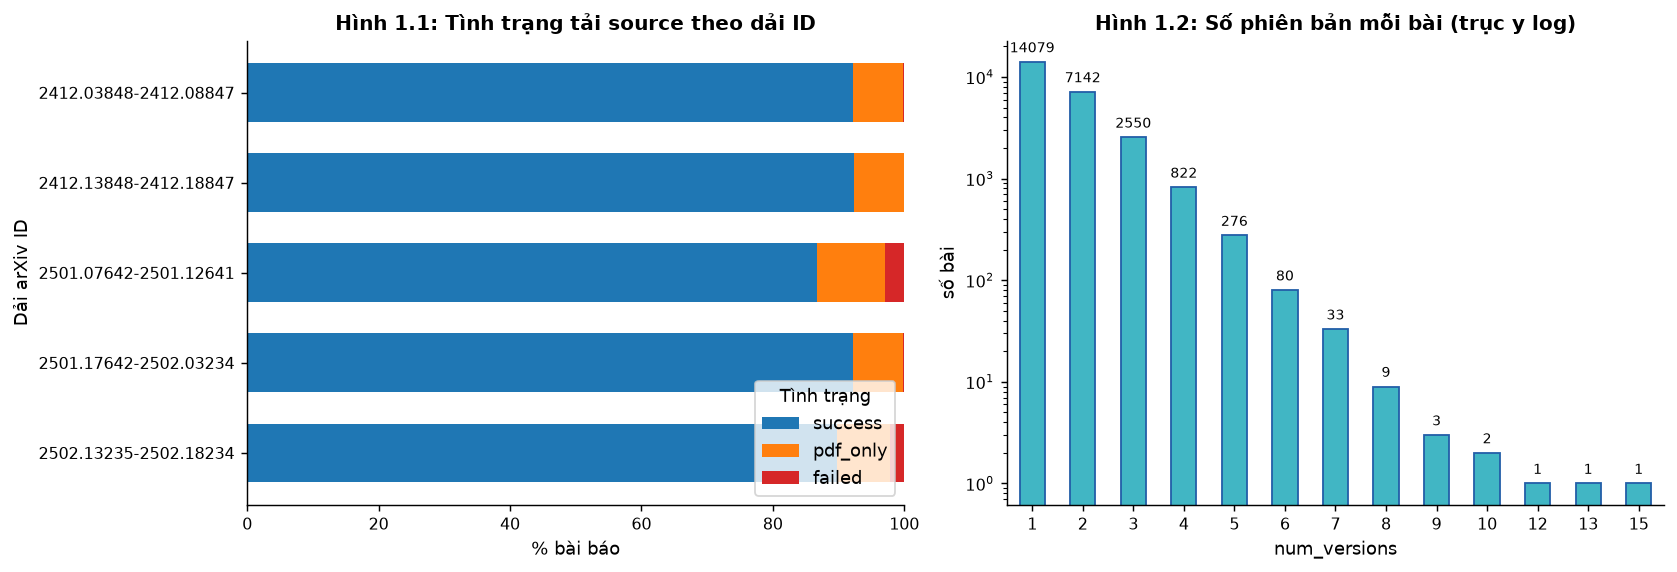

In [2]:
if summary:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    dl_range = summary.get("download_status_by_range", {})
    if dl_range:
        df_dl = pd.DataFrame(dl_range).T
        cols = [c for c in ["success", "pdf_only", "failed"] if c in df_dl.columns]
        df_dl[cols].sort_index(ascending=False).plot(
            kind="barh", stacked=True, ax=axes[0], width=0.65,
            color=["#1f77b4", "#ff7f0e", "#d62728"]
        )
        axes[0].set(xlim=(0, 100), xlabel="% bài báo", ylabel="Dải arXiv ID",
                    title="Hình 1.1: Tình trạng tải source theo dải ID")
        axes[0].legend(["success", "pdf_only", "failed"], title="Tình trạng", loc="lower right", frameon=True)
    v_dist = summary.get("version_distribution", {})
    if v_dist:
        s_ver = pd.Series({int(k): v for k, v in v_dist.items()}).sort_index()
        ax_v = s_ver.plot.bar(ax=axes[1], rot=0, logy=True, color="#41b6c4", edgecolor="#225ea8",
                              title="Hình 1.2: Số phiên bản mỗi bài (trục y log)")
        ax_v.set(xlabel="num_versions", ylabel="số bài")
        for i, val in enumerate(s_ver.values):
            ax_v.text(i, val * 1.15, str(val), ha="center", va="bottom", fontsize=8)
    plt.tight_layout()
    plt.show()

*Nhận xét từ Hình 1.1 và Hình 1.2:*  
- **So sánh kết quả tải nguồn giữa các dải ID (Hình 1.1):**   Tỷ lệ cào mã nguồn giữa 5 thành viên khá đồng đều, lượng bài lấy được TeX thành công đều duy trì ổn định từ 87% đến 92%, còn tỷ lệ bài `PDF-only` dao động quanh mốc 7%–10%. Ở hai dải `2501.07642-2501.12641` và `2502.13235-2502.18234`, vạch đỏ `failed` nhỉnh hơn một chút (khoảng 2.2%–3%). Nguyên nhân là trong một số khung giờ chạy batch của hai dải này, máy chủ `export.arxiv.org` bị nghẽn băng thông khiến việc tải các gói `.tar.gz` nặng bị timeout sau nhiều lần thử lại (retry). Toàn bộ các mã bài lỗi này đều đã được ghi nhận rõ trong manifest.  
- **Phân bố số lượng phiên bản (Hình 1.2):** Số phiên bản của một bài báo giảm rất nhanh theo phân bố lệch phải (biểu diễn trên trục log). Hơn một nửa tập dữ liệu (14.079 bài, tương đương 56.3%) chỉ dừng lại ở phiên bản đầu tiên ($v1$). Khoảng 28.6% số bài có 2 phiên bản — thường là bản tác giả chỉnh sửa lại sau vòng phản biện (peer-review) hoặc bổ sung thực nghiệm. Số bài chỉnh sửa từ 4 phiên bản trở lên chỉ chiếm khoảng 4.9%, nhưng có những bài đặc biệt cập nhật tới 12–17 lần. 

### 1.2.2. Phân bố Trích dẫn Học thuật và Kích thước Tệp Nguồn

Tiếp theo, nhóm khảo sát số lượng trích dẫn học thuật thu được từ Semantic Scholar (Hình 1.3) và sự thay đổi kích thước của tệp nguồn sau khi giải nén và lọc ảnh (Hình 1.4):


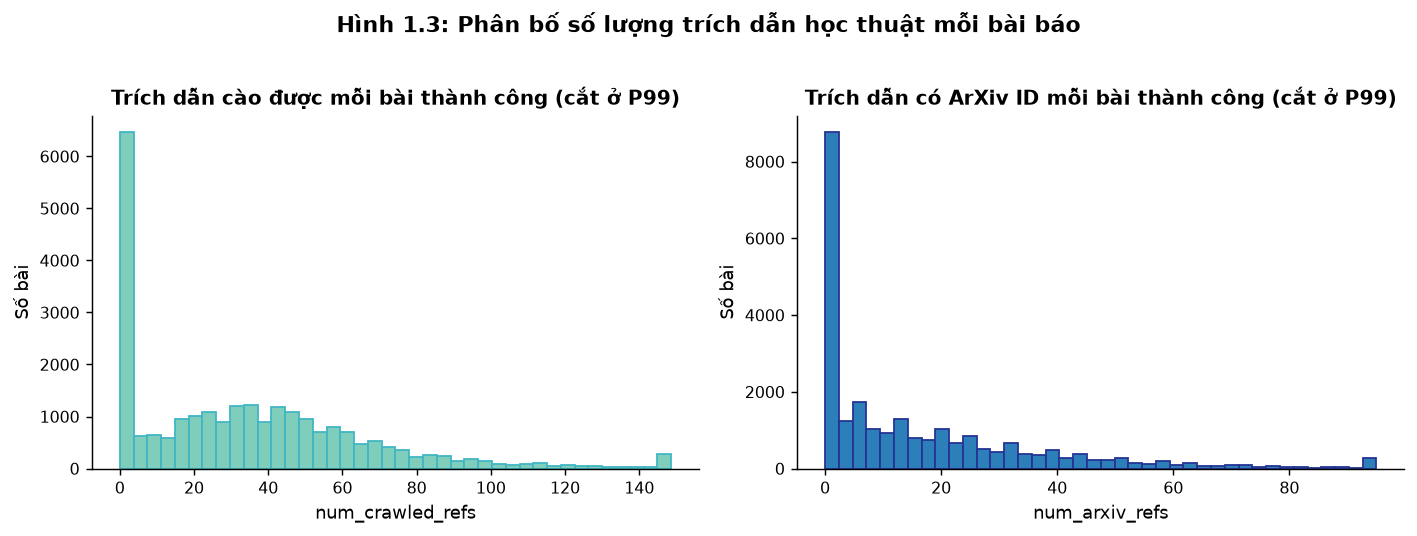

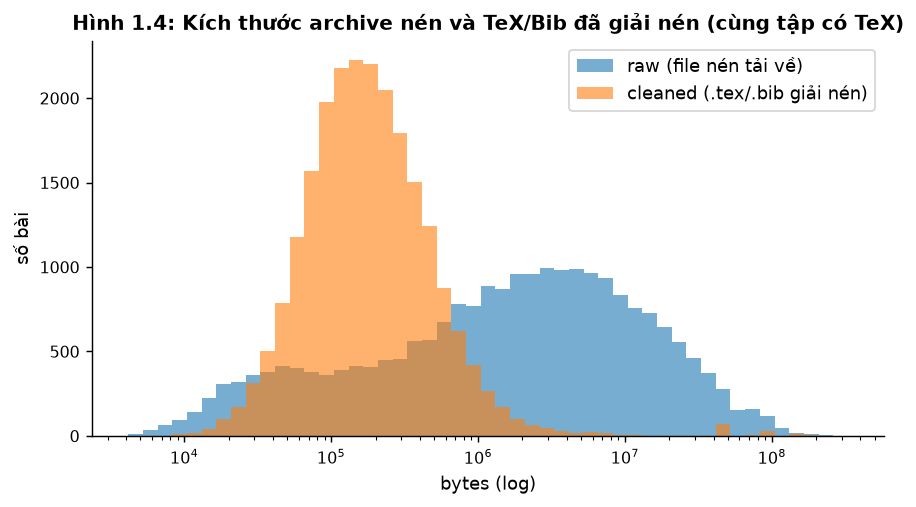

In [3]:
if summary and "hist_data" in summary:
    hd = summary["hist_data"]
    ref_h = hd.get("refs", {})
    if ref_h:
        fig, axes = plt.subplots(1, 2, figsize=(11, 4))
        c_edges = np.array(ref_h["crawled_edges"])
        c_counts = np.array(ref_h["crawled_counts"])
        axes[0].bar(c_edges[:-1], c_counts, width=np.diff(c_edges), align="edge", color="#7fcdbb", edgecolor="#41b6c4")
        axes[0].set_title("Trích dẫn cào được mỗi bài thành công (cắt ở P99)")
        axes[0].set_xlabel("num_crawled_refs")
        axes[0].set_ylabel("Số bài")
        a_edges = np.array(ref_h["arxiv_edges"])
        a_counts = np.array(ref_h["arxiv_counts"])
        axes[1].bar(a_edges[:-1], a_counts, width=np.diff(a_edges), align="edge", color="#2c7fb8", edgecolor="#253494")
        axes[1].set_title("Trích dẫn có ArXiv ID mỗi bài thành công (cắt ở P99)")
        axes[1].set_xlabel("num_arxiv_refs")
        axes[1].set_ylabel("Số bài")
        plt.suptitle("Hình 1.3: Phân bố số lượng trích dẫn học thuật mỗi bài báo", fontweight="bold", y=1.02)
        plt.tight_layout()
        plt.show()
    sz_h = hd.get("sizes", {})
    if sz_h:
        bins = np.array(sz_h["bins"])
        raw_c = np.array(sz_h["raw_counts"])
        cln_c = np.array(sz_h["clean_counts"])
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.stairs(raw_c, bins, fill=True, alpha=0.6, color="#1f77b4", label="raw (file nén tải về)")
        ax.stairs(cln_c, bins, fill=True, alpha=0.6, color="#ff7f0e", label="cleaned (.tex/.bib giải nén)")
        ax.set_xscale("log")
        ax.set_xlabel("bytes (log)")
        ax.set_ylabel("số bài")
        ax.legend()
        ax.set_title("Hình 1.4: Kích thước archive nén và TeX/Bib đã giải nén (cùng tập có TeX)")
        plt.tight_layout()
        plt.show()

*Nhận xét từ Hình 1.3 và Hình 1.4:*  
- **Phân bố số lượng trích dẫn (Hình 1.3):**  
 Biểu đồ phân bố trích dẫn lệch phải rõ rệt, phần lớn các bài báo trích dẫn trong khoảng 20 đến 50 tài liệu. Có khoảng 24% số bài trả về 0 trích dẫn từ Semantic Scholar; khi nhóm kiểm tra trực tiếp một số mã bài này thì thấy đây hầu hết là các bài vừa mới đăng lên arXiv vào đợt tháng 1 và tháng 2/2025, hệ thống của Semantic Scholar chưa kịp bóc tách xong danh mục tham khảo từ PDF. Tuy vậy, trên toàn tập dữ liệu vẫn có tới 71% số bài chứa ít nhất 1 trích dẫn có mã arXiv (trung bình 16.7 trích dẫn arXiv/bài).
- **Hiệu quả giảm dung lượng nhờ lọc bỏ file ảnh (Hình 1.4):**   
Khi dùng thang đo logarit, sự chênh lệch kích thước trước và sau khi làm sạch thể hiện rất rõ. Một gói nén `.tar.gz` tải về (`raw_size_bytes`) nặng trung bình 7.42 MB (trung vị 1.9 MB) do gánh toàn bộ hình vẽ, biểu đồ độ phân giải cao. Sau khi giải nén và chỉ lọc giữ lại văn bản `.tex`/`.bib` (`cleaned_size_bytes`), dung lượng trung bình mỗi bài rút xuống chỉ còn khoảng 715 KB (trung vị 169 KB) — tiết kiệm hơn 90% dung lượng ổ đĩa cho cả nhóm.


### 1.2.3. Cấu trúc Tệp TeX, Tỷ lệ PDF-only và Phân loại Chuyên ngành

Mục này đi sâu vào việc mỗi bài báo chứa bao nhiêu file `.tex`, mối liên hệ giữa số phiên bản với bài PDF-only (Hình 1.5), và đặc điểm của các chuyên ngành trên arXiv (Hình 1.6 & Bảng 1.2):


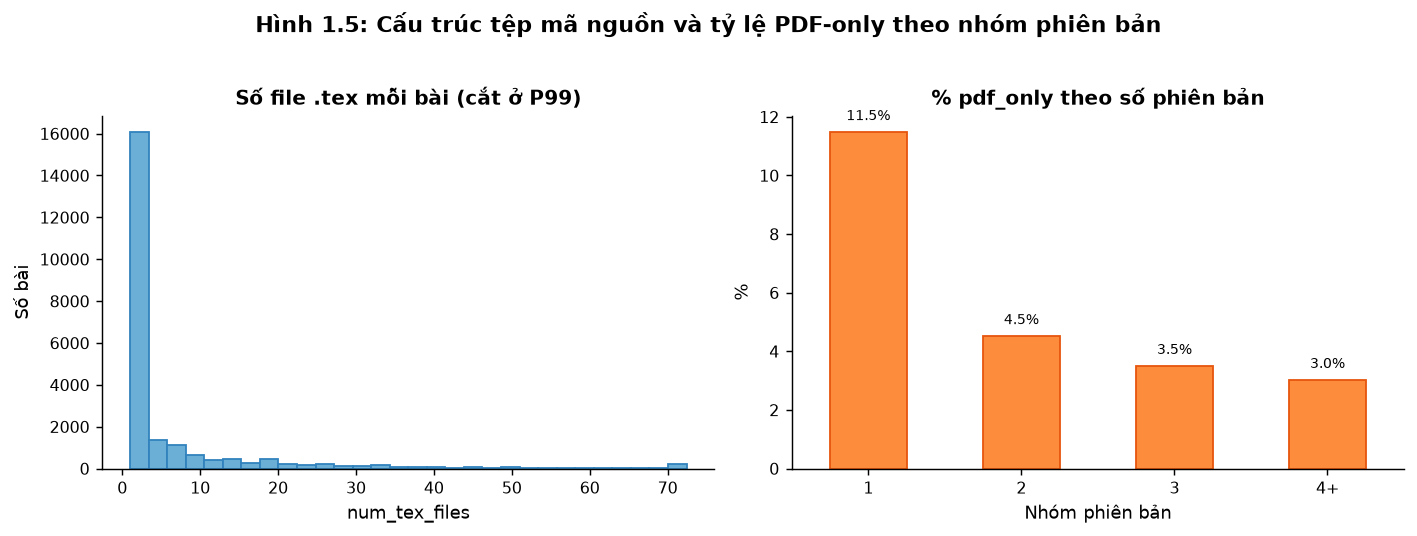

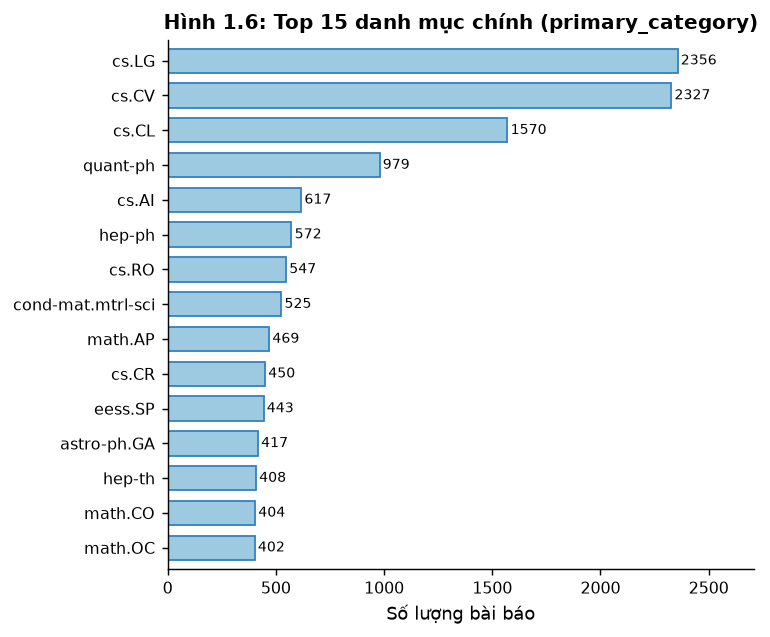

#### Bảng 1.2: Tương quan Chất lượng và Tỷ lệ PDF-only theo Top 10 Danh mục

,Số bài,Tỷ lệ PDF-only,Refs TB,Versions TB
cs.LG,2356.0,5.20%,38.5,1.80
cs.CV,2327.0,4.30%,42.9,1.70
cs.CL,1570.0,6.00%,38.0,1.81
quant-ph,979.0,3.20%,40.6,1.83
cs.AI,617.0,8.90%,35.7,1.70
hep-ph,572.0,0.30%,38.2,1.78
cs.RO,547.0,4.40%,36.5,1.67
cond-mat.mtrl-sci,525.0,44.00%,39.0,1.43
math.AP,469.0,0.20%,23.3,1.56
cs.CR,450.0,10.70%,37.3,1.63


In [4]:
if summary and "hist_data" in summary:
    hd = summary["hist_data"]
    tex_h = hd.get("tex_files", {})
    pdf_v = hd.get("pdf_by_ver_group", {})
    if tex_h and pdf_v:
        fig, axes = plt.subplots(1, 2, figsize=(11, 4))
        t_edges = np.array(tex_h["edges"])
        t_counts = np.array(tex_h["counts"])
        axes[0].bar(t_edges[:-1], t_counts, width=np.diff(t_edges), align="edge", color="#6baed6", edgecolor="#3182bd")
        axes[0].set_title("Số file .tex mỗi bài (cắt ở P99)")
        axes[0].set_xlabel("num_tex_files")
        axes[0].set_ylabel("Số bài")
        s_pdf = pd.Series(pdf_v)
        s_pdf.plot.bar(ax=axes[1], rot=0, color="#fd8d3c", edgecolor="#e6550d")
        axes[1].set_title("% pdf_only theo số phiên bản")
        axes[1].set_xlabel("Nhóm phiên bản")
        axes[1].set_ylabel("%")
        for i, val in enumerate(s_pdf.values):
            axes[1].text(i, val + 0.3, f"{val:.1f}%", ha="center", va="bottom", fontsize=8)
        plt.suptitle("Hình 1.5: Cấu trúc tệp mã nguồn và tỷ lệ PDF-only theo nhóm phiên bản", fontweight="bold", y=1.02)
        plt.tight_layout()
        plt.show()
    cat15 = summary.get("category_top15", {})
    if cat15:
        fig, ax = plt.subplots(figsize=(6, 5))
        s_cat = pd.Series(cat15).sort_values(ascending=True)
        s_cat.plot.barh(ax=ax, color="#9ecae1", edgecolor="#3182bd", width=0.7)
        ax.set_title("Hình 1.6: Top 15 danh mục chính (primary_category)")
        ax.set_xlabel("Số lượng bài báo")
        for i, val in enumerate(s_cat.values):
            ax.text(val + 15, i, str(val), va="center", fontsize=8)
        ax.set_xlim(0, max(s_cat.values) * 1.15)
        plt.tight_layout()
        plt.show()
    cat_qual = summary.get("category_vs_quality_top10", {})
    if cat_qual:
        display(Markdown("#### Bảng 1.2: Tương quan Chất lượng và Tỷ lệ PDF-only theo Top 10 Danh mục"))
        df_cq = pd.DataFrame(cat_qual).T.rename(columns={
            "so_bai": "Số bài",
            "pdf_only": "Tỷ lệ PDF-only",
            "refs_tb_successful": "Refs TB",
            "versions_tb": "Versions TB"
        })
        df_cq["Tỷ lệ PDF-only"] = df_cq["Tỷ lệ PDF-only"].map(lambda x: f"{x:.2%}")
        df_cq["Refs TB"] = df_cq["Refs TB"].map(lambda x: f"{x:.1f}")
        df_cq["Versions TB"] = df_cq["Versions TB"].map(lambda x: f"{x:.2f}")
        display(df_cq)

*Nhận xét từ Hình 1.5, Hình 1.6 và Bảng 1.2:*  
- **Cấu trúc tổ chức file `.tex` của tác giả (Hình 1.5 trái):**  
 Hơn 60% số bài báo trên arXiv gộp toàn bộ nội dung vào đúng 1 file `.tex` duy nhất. Tuy nhiên, phần đuôi phân bố kéo dài cho thấy có khá nhiều công trình lớn được tác giả tách nhỏ thành 5 đến 20 file `.tex` (chia theo từng mục `introduction.tex`, `method.tex`, `experiments.tex`...) rồi gọi ghép vào file gốc qua lệnh `\input{}` hoặc `\include{}`. Đặc điểm này nhắc nhở nhóm khi thiết kế bộ Parser ở Milestone 2 bắt buộc phải có bước đệ quy nối file (flattening) trước khi dựng cây phân cấp.
- **Tương quan giữa số phiên bản và tỷ lệ PDF-only (Hình 1.5 phải):**   
Nhìn vào biểu đồ cột, những bài chỉ có đúng 1 phiên bản ($v1$) có tỷ lệ `PDF-only` khá cao (**11.5%**). Ngược lại, một khi bài báo đã có từ 2 phiên bản trở lên, tỷ lệ `PDF-only` giảm mạnh xuống chỉ còn **3%–4.5%**. Điều này phản ánh đúng thực tế: các nhóm nghiên cứu có thói quen cập nhật, chỉnh sửa bản thảo nhiều lần qua các vòng hội nghị hầu hết đều soạn thảo bằng LaTeX.
- **Đặc thù phân bố chuyên ngành trên arXiv (Hình 1.6 & Bảng 1.2):**  
 Đứng đầu tập dữ liệu là các lĩnh vực mũi nhọn của Khoa học Máy tính gồm Học máy (`cs.LG`), Thị giác máy tính (`cs.CV`), Xử lý ngôn ngữ tự nhiên (`cs.CL`) và Vật lý lượng tử (`quant-ph`). Khi đối chiếu sang Bảng 1.2, trong khi các ngành Toán học (`math.AP`) và Vật lý năng lượng cao (`hep-ph`) gần như tuyệt đối dùng LaTeX (tỷ lệ `PDF-only` chỉ 0.20%–0.30%), hoặc khối ngành AI/CS duy trì mức `PDF-only` thấp quanh 4%–10%, thì riêng chuyên ngành **Khoa học Vật liệu (`cond-mat.mtrl-sci`) lại có tỷ lệ `PDF-only` vọt lên tới 44.00%**. Nguyên nhân xuất phát từ văn hóa xuất bản của cộng đồng thực nghiệm Vật liệu và Hóa học: các tác giả thường soạn thảo bản thảo trên Microsoft Word rồi xuất ra PDF nộp lên arXiv thay vì viết code LaTeX.

---

## 1.3. Phân tích Độ phủ Phiên bản (Version Coverage)

 Nhóm đã ghi log toàn bộ quá trình tải từng phiên bản vào `versions_manifest.jsonl` và thống kê lại ở Hình 1.7 và Bảng 1.3:


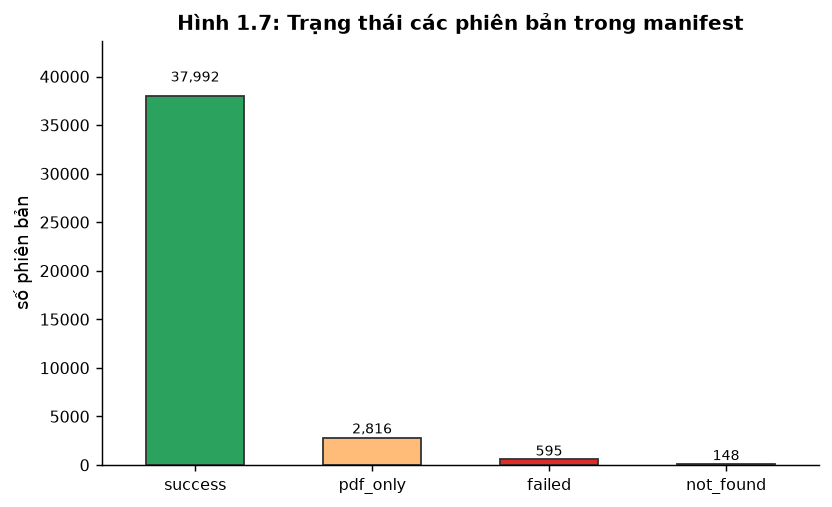

#### Bảng 1.3: Thống kê Độ phủ Phiên bản (Version Coverage)

,Giá trị
Chỉ số,
Số bài có trong manifest,"24,999"
Tổng số phiên bản dự kiến,"41,551"
Tổng số phiên bản đã xử lý trong manifest,"41,551"
Tỷ lệ độ phủ giải quyết (Coverage Resolved),98.57%
Tỷ lệ độ phủ nội dung (Coverage Content),98.21%
Tỷ lệ bài báo được phủ trọn vẹn 100% phiên bản,97.60%


In [5]:
if summary:
    cov_info = summary.get("version_coverage", {})
    src_statuses = summary.get("source_statuses", {})
    if src_statuses:
        status_labels = {
            "verified_success": "success",
            "verified_pdf_only": "pdf_only",
            "failed": "failed",
            "not_found": "not_found",
        }
        fig, ax = plt.subplots(figsize=(6.5, 4))
        plot_data = pd.Series({label: src_statuses.get(k, 0) for k, label in status_labels.items() if k in src_statuses})
        plot_data.plot.bar(ax=ax, rot=0, color=["#2ca25f", "#ffbc79", "#de2d26", "#999999"], width=0.55, edgecolor="#333333")
        ax.set_title("Hình 1.7: Trạng thái các phiên bản trong manifest")
        ax.set_ylabel("số phiên bản")
        for i, val in enumerate(plot_data.values):
            ax.text(i, val * 1.03, f"{val:,}", ha="center", va="bottom", fontsize=8)
        ax.set_ylim(0, max(plot_data.values) * 1.15)
        plt.tight_layout()
        plt.show()
    if cov_info:
        display(Markdown("#### Bảng 1.3: Thống kê Độ phủ Phiên bản (Version Coverage)"))
        cov_table = pd.DataFrame([
            {"Chỉ số": "Số bài có trong manifest", "Giá trị": f"{cov_info.get('papers_in_manifest', 24999):,}"},
            {"Chỉ số": "Tổng số phiên bản dự kiến", "Giá trị": f"{cov_info.get('versions_discovered', 41551):,}"},
            {"Chỉ số": "Tổng số phiên bản đã xử lý trong manifest", "Giá trị": f"{cov_info.get('versions_in_manifest', 41551):,}"},
            {"Chỉ số": "Tỷ lệ độ phủ giải quyết (Coverage Resolved)", "Giá trị": f"{cov_info.get('coverage_resolved', 0.9857):.2%}"},
            {"Chỉ số": "Tỷ lệ độ phủ nội dung (Coverage Content)", "Giá trị": f"{cov_info.get('coverage_content', 0.9821):.2%}"},
            {"Chỉ số": "Tỷ lệ bài báo được phủ trọn vẹn 100% phiên bản", "Giá trị": f"{cov_info.get('papers_fully_covered', 0.976):.2%}"},
        ]).set_index("Chỉ số")
        display(cov_table)

*Nhận xét từ Hình 1.7 và Bảng 1.3:*  
Tổng hợp từ tệp nhật ký `versions_manifest.jsonl` cho thấy mức độ hoàn thiện rất cao ở cấp độ phiên bản:  
- Hệ thống đã duyệt qua toàn bộ **41.551 phiên bản** của 24.999 bài báo, thu về thành công 37.992 phiên bản có mã nguồn TeX và xác nhận rõ 2.816 phiên bản thuộc diện `PDF-only`.
- **Độ phủ nội dung (Coverage Content) đạt 98.21%**, và có tới **97.60% số bài báo được thu thập trọn vẹn 100% các phiên bản hiện có**.  
- Khoảng 2.4% số bài bị khuyết một vài phiên bản chủ yếu rơi vào lỗi mạng cục bộ lúc tải file hoặc lỗi `not_found` (HTTP 404 — 148 phiên bản). Khi nhóm mở trình duyệt kiểm tra thủ công một số đường dẫn báo 404 này trên trang chủ arXiv, nguyên nhân là do tác giả đã rút lại phiên bản đó (withdrawn) hoặc bản thân kho lưu trữ arXiv không còn lưu gói source của version trung gian đó nữa.

---

## 1.4. Hiệu năng Hệ thống (Benchmark trên Google Colab CPU-only)

Toàn bộ quá trình cào dữ liệu được đo kiểm bằng module `SystemBenchmarkTracker` trên môi trường thực nghiệm chuẩn **Google Colab CPU-only** (2 vCPU, 12GB RAM, 100GB Disk):


#### Bảng 1.4: Tổng hợp Hiệu năng Hệ thống trên Google Colab CPU-only

Giá trị
Nhóm chỉ số                   Tham số                                                                 
Thời gian (Running Time)      Môi trường thử nghiệm                              Google Colab CPU-only
                              Tổng số bài báo đo đạc                                        24,999 bài
                              Tổng thời gian chạy toàn hệ thống (Wall Time)    94.57 giờ (340,465.9 s)
                              Thời gian xử lý trung bình 1 bài                          13.62 giây/bài
                              Tổng thời gian Entry Discovery                    0.41 giờ (0.059 s/bài)
                              Tổng thời gian Source Download                   81.80 giờ (11.78 s/bài)
                              Tổng thời gian Reference Crawling                  3.22 giờ (0.46 s/bài)
Tài nguyên (Memory Footprint) RAM tiêu thụ trung bình (Weighted Average RAM)                 410.78 MB
                              RAM tiêu thụ tối đa (Peak RAM)                    5,450.45 MB (~5.32 GB)
                              Dung lượng đĩa cục bộ đỉnh (Peak Disk)            6,277.25 MB (~6.13 GB)
                              Dung lượng dữ liệu thành phẩm cuối cùng         14,975.53 MB (~14.62 GB)

#### Bảng 1.5: Thống kê Hiệu năng theo từng Dải arXiv ID (5 Thành viên)

,Số đợt,Số bài,Tổng giờ,Giây/bài,RAM đỉnh (MB),RAM TB (MB),Đĩa đỉnh (MB),Storage cuối (MB)
2412.03848-2412.08847,5.0,5000.0,12.79,9.21,335.64,241.42,782.82,327.17
2412.13848-2412.18847,5.0,5000.0,19.80,14.26,4904.54,552.19,3933.38,3705.88
2501.07642-2501.12641,10.0,5000.0,20.99,15.11,2977.62,252.20,2268.55,2037.56
2501.17642-2502.03234,11.0,4999.0,21.06,15.17,5450.45,605.12,3160.88,2847.14
2502.13235-2502.18234,5.0,5000.0,19.93,14.35,3165.57,340.57,6277.25,6057.78


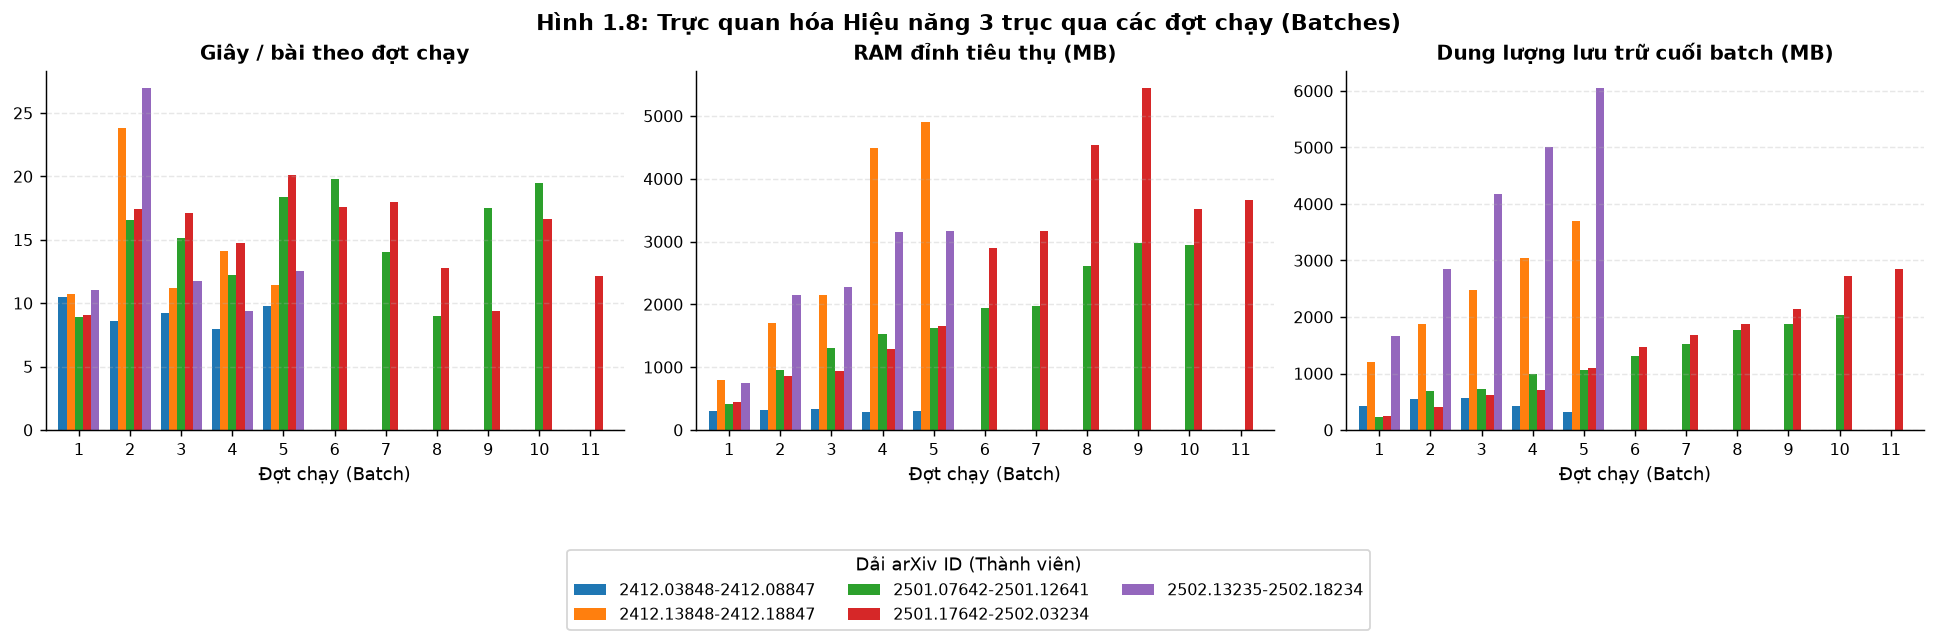

In [6]:
if summary:
    bench_data = summary.get("benchmark_evidence", {}).get("official_version_pipeline_metrics", {})
    if bench_data:
        display(Markdown("#### Bảng 1.4: Tổng hợp Hiệu năng Hệ thống trên Google Colab CPU-only"))
        perf_summary = pd.DataFrame([
            {"Nhóm chỉ số": "Thời gian (Running Time)", "Tham số": "Môi trường thử nghiệm", "Giá trị": bench_data.get("testbed", "Google Colab CPU-only")},
            {"Nhóm chỉ số": "Thời gian (Running Time)", "Tham số": "Tổng số bài báo đo đạc", "Giá trị": f"{bench_data.get('total_papers', 24999):,} bài"},
            {"Nhóm chỉ số": "Thời gian (Running Time)", "Tham số": "Tổng thời gian chạy toàn hệ thống (Wall Time)", "Giá trị": f"{bench_data.get('total_wall_time_hours', 94.57):.2f} giờ ({bench_data.get('total_wall_time_sec', 340465.88):,.1f} s)"},
            {"Nhóm chỉ số": "Thời gian (Running Time)", "Tham số": "Thời gian xử lý trung bình 1 bài", "Giá trị": f"{bench_data.get('avg_sec_per_paper', 13.62):.2f} giây/bài"},
            {"Nhóm chỉ số": "Thời gian (Running Time)", "Tham số": "Tổng thời gian Entry Discovery", "Giá trị": f"{bench_data.get('discovery_total_hours', 0.41):.2f} giờ ({bench_data.get('discovery_avg_sec_per_paper', 0.059):.3f} s/bài)"},
            {"Nhóm chỉ số": "Thời gian (Running Time)", "Tham số": "Tổng thời gian Source Download", "Giá trị": f"{bench_data.get('download_total_hours', 81.80):.2f} giờ ({bench_data.get('download_avg_sec_per_paper', 11.78):.2f} s/bài)"},
            {"Nhóm chỉ số": "Thời gian (Running Time)", "Tham số": "Tổng thời gian Reference Crawling", "Giá trị": f"{bench_data.get('reference_total_hours', 3.22):.2f} giờ ({bench_data.get('reference_avg_sec_per_paper', 0.46):.2f} s/bài)"},
            {"Nhóm chỉ số": "Tài nguyên (Memory Footprint)", "Tham số": "RAM tiêu thụ trung bình (Weighted Average RAM)", "Giá trị": f"{bench_data.get('weighted_avg_ram_mb', 410.78):,.2f} MB"},
            {"Nhóm chỉ số": "Tài nguyên (Memory Footprint)", "Tham số": "RAM tiêu thụ tối đa (Peak RAM)", "Giá trị": f"{bench_data.get('peak_ram_mb', 5450.45):,.2f} MB (~5.32 GB)"},
            {"Nhóm chỉ số": "Tài nguyên (Memory Footprint)", "Tham số": "Dung lượng đĩa cục bộ đỉnh (Peak Disk)", "Giá trị": f"{bench_data.get('peak_disk_mb', 6277.25):,.2f} MB (~6.13 GB)"},
            {"Nhóm chỉ số": "Tài nguyên (Memory Footprint)", "Tham số": "Dung lượng dữ liệu thành phẩm cuối cùng", "Giá trị": f"{bench_data.get('final_storage_mb', 14975.53):,.2f} MB (~14.62 GB)"},
        ]).set_index(["Nhóm chỉ số", "Tham số"])
        display(perf_summary)
        per_mem = bench_data.get("per_member", {})
        if per_mem:
            display(Markdown("#### Bảng 1.5: Thống kê Hiệu năng theo từng Dải arXiv ID (5 Thành viên)"))
            df_pm = pd.DataFrame(per_mem).T.rename(columns={
                "batches": "Số đợt",
                "papers": "Số bài",
                "wall_time_hours": "Tổng giờ",
                "sec_per_paper": "Giây/bài",
                "peak_ram_mb": "RAM đỉnh (MB)",
                "avg_ram_mb": "RAM TB (MB)",
                "peak_disk_mb": "Đĩa đỉnh (MB)",
                "final_storage_mb": "Storage cuối (MB)"
            })
            display(df_pm)
    hd = summary.get("hist_data", {})
    b_piv = hd.get("bench_pivots", {})
    if b_piv:
        fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
        titles = [("sec_per_paper", "Giây / bài theo đợt chạy"),
                  ("peak_ram_mb", "RAM đỉnh tiêu thụ (MB)"),
                  ("final_storage_mb", "Dung lượng lưu trữ cuối batch (MB)")]
        legend_handles, legend_labels = None, None
        for a, (col, title) in zip(ax, titles):
            df_col = pd.DataFrame(b_piv[col]).T
            df_col.index = df_col.index.astype(int)
            df_col = df_col.sort_index()
            plot = df_col.plot.bar(ax=a, rot=0, title=title, legend=(col == "sec_per_paper"), width=0.8)
            a.set_xlabel("Đợt chạy (Batch)")
            a.grid(True, linestyle="--", alpha=0.3, axis="y")
            if col == "sec_per_paper":
                legend_handles, legend_labels = plot.get_legend_handles_labels()
                plot.get_legend().remove()
        if legend_handles:
            clean_labels = [lbl.replace("m1_version_pipeline_benchmark(", "").replace(").csv", "") for lbl in legend_labels]
            fig.legend(legend_handles, clean_labels, title="Dải arXiv ID (Thành viên)",
                       loc="lower center", bbox_to_anchor=(0.5, -0.10), ncol=3, frameon=True, fontsize=9)
        fig.tight_layout(rect=(0, 0.14, 1, 1))
        plt.suptitle("Hình 1.8: Trực quan hóa Hiệu năng 3 trục qua các đợt chạy (Batches)", fontweight="bold", y=1.02)
        plt.show()

*Nhận xét từ Bảng 1.4, Bảng 1.5 và Hình 1.8:*
- **Về thời gian thực thi (Running Time):**  
 Để thu thập trọn vẹn 24.999 bài báo (41.551 phiên bản) trên môi trường Google Colab CPU-only, tổng thời gian chạy thực tế (Wall Time) của cả 5 thành viên cộng lại là **94.57 giờ** (trung bình mất **13.62 giây cho mỗi bài báo**). Nhìn vào biểu đồ phân rã thời gian ở Hình 1.8, khâu **Tải và giải nén mã nguồn (Source Download)** chiếm tới **86.5% tổng thời gian (81.80 giờ)** do phải tải hàng chục nghìn gói `.tar.gz`, giải nén, xóa file ảnh và đồng bộ hàng trăm nghìn file nhỏ xuống ổ đĩa, cộng thêm thời gian chờ `sleep` 3 giây giữa các request theo quy định của arXiv. Trong khi đó, khâu cào Metadata (0.41 giờ) và cào Reference qua Semantic Scholar API có gắn Key (3.22 giờ) diễn ra rất nhanh.
- **Về mức tiêu thụ tài nguyên (RAM & Disk):**  
 Nhờ thiết kế xử lý cuốn chiếu theo từng lô (batch) 500–1.000 bài và giải phóng bộ nhớ liên tục, mức **RAM trung bình có trọng số chỉ tốn khoảng 410.78 MB**, và mức đỉnh (Peak RAM) cao nhất ghi nhận được là **5.32 GB** — hoàn toàn nằm trong ngưỡng an toàn của cấu hình Google Colab miễn phí (12.7 GB RAM), không xảy ra tình trạng tràn bộ nhớ (OOM).
- **Về dung lượng lưu trữ cuối cùng (Final Storage):**   
Toàn bộ dữ liệu thô đã làm sạch của 24.999 bài báo chiếm **14.62 GB (14,975.53 MB)**. Ở dải đầu tiên (`2412.03848-2412.08847`), tốc độ xử lý nhanh hơn (9.21 giây/bài) và dung lượng lưu trữ nhỏ hơn các dải sau do thành viên phụ trách chạy trực tiếp trên ổ đĩa tạm cục bộ (`/content/`) của máy ảo Colab thay vì ghi trực tiếp qua lớp đồng bộ Google Drive FUSE chậm hơn như các dải còn lại.

---

## 1.5. Đánh giá Chất lượng Dữ liệu & Chuẩn bị cho Milestone 2

### 1.5.1. Các vấn đề kỹ thuật đã xử lý
- **Lỗi mất số 0 ở arXiv ID:** Khi lưu ra CSV, một số ID như `2412.03848` hay bị phần mềm tự ép về số thực làm mất số 0 cuối. Nhóm đã kịp thời phát hiện và viết regex chuẩn hóa lại toàn bộ, tránh được việc bị lệch khóa chính khi join bảng.
- **Hạn chế của Semantic Scholar:** API này chỉ trả về trích dẫn ở cấp bài báo chứ không phân biệt theo từng phiên bản $v1, v2$. Ngoài ra khoảng 24% bài mới chưa có trích dẫn. Nhóm quyết định giữ nguyên trạng thái dữ liệu thô thay vì tự ý bịa số liệu.
- **Xử lý các bài PDF-only:** Nhóm tạo các bản ghi rỗng có cấu trúc tương thích thay vì xóa bỏ, đảm bảo số lượng bài khớp đúng 100% với danh mục được giao.

### 1.5.2. Chuyển giao sang Milestone 2
Tập dữ liệu 24.999 bài báo và 41.551 phiên bản đã được thu thập, kiểm tra toàn vẹn và đóng gói hoàn tất. Nhóm đã sẵn sàng chuyển giao dữ liệu sang Milestone 2 để thực hiện:
1. Phân tích cú pháp TeX thành cây phân cấp (`tex_parser.py`).
2. Bóc tách và chuẩn hóa trích dẫn `\bibitem` sang định dạng BibTeX (`bib_parser.py`).
3. Khử trùng lặp nội dung giữa các phiên bản bài báo (`deduplicator.py`).
